In [1]:
datoteka = '/home/gueswho/Documents/Faks/Magistrska/Paper_II/A2-001/Asiago/20210222_ech_a2-001_hv_c.fits'  # Vnesi svoje ime datoteke

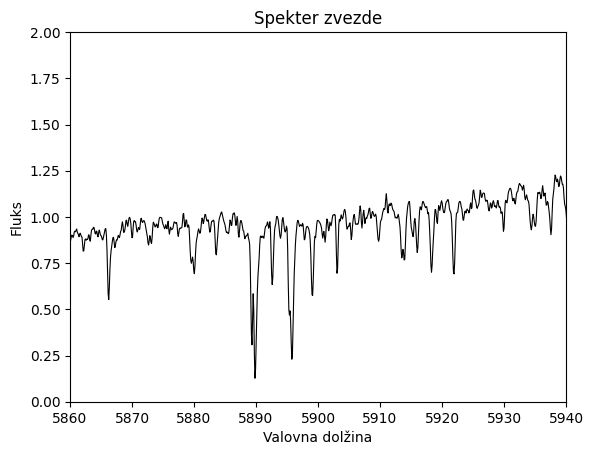

In [2]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

# 1. Odpri FITS datoteko
hdul = fits.open(datoteka)

# Pri 1D spektrih so podatki (fluks) običajno že v primarnem HDU (indeks 0)
podatki = hdul[0].data
glava = hdul[0].header

# Če v HDU 0 slučajno ni podatkov, vzamemo HDU 1
if podatki is None:
    podatki = hdul[1].data
    glava = hdul[1].header

# Ker ne gre za tabelo, so "podatki" že neposredno naš fluks
# (če ima oblika niza več dimenzij, npr. [1, 4000], vzamemo prvo vrstico: podatki[0])
if podatki.ndim > 1:
    fluks = podatki[0]
else:
    fluks = podatki

# 2. Izračun valovne dolžine iz glave (WCS - World Coordinate System)
try:
    zacetek = glava['CRVAL1']      # Začetna vrednost osi x (referenčna val. dolžina)
    korak = glava['CDELT1']        # Korak (koliko val. dolžine zajame 1 piksel)
    ref_piksel = glava['CRPIX1']   # Referenčni piksel (običajno piksel 1)
    
    # Izračunamo valovno dolžino za vsak piksel fluksa posebej
    piksli = np.arange(len(fluks))
    valovna_dolzina = zacetek + (piksli - (ref_piksel - 1)) * korak
    x_oznaka = 'Valovna dolžina'
    
except KeyError:
    # Če datoteka nima teh parametrov, rišemo kar po zaporednih številkah pikslov
    print("Opozorilo: V glavi manjkajo podatki o valovni dolžini. Rišem po pikslih.")
    valovna_dolzina = np.arange(len(fluks))
    x_oznaka = 'Piksli'

# 3. Prikaz spektra
plt.plot(valovna_dolzina, fluks, color='black', linewidth=0.8)
plt.xlabel(x_oznaka)
plt.ylabel('Fluks')
plt.xlim(5860,5940)
plt.ylim(0,2)
plt.title('Spekter zvezde')
plt.show()

# 4. Zapri datoteko
hdul.close()

In [5]:
datoteka = '/home/gueswho/Documents/Faks/Magistrska/Paper_II/A2-001/Varese/20210224_ech_a2-001_hv_f.fits'  # Vnesi svoje ime datoteke

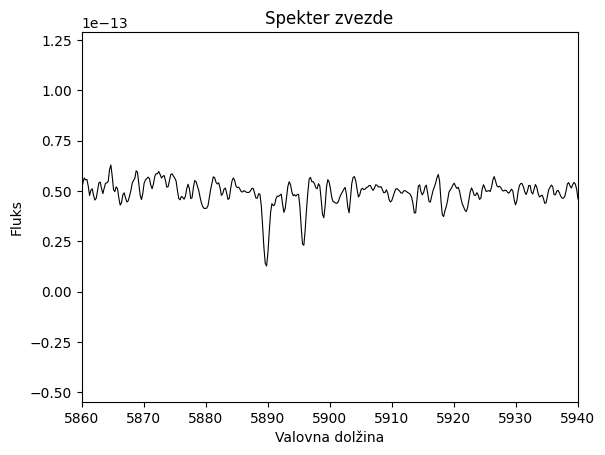

In [7]:
# 1. Odpri FITS datoteko
hdul = fits.open(datoteka)

# Pri 1D spektrih so podatki (fluks) običajno že v primarnem HDU (indeks 0)
podatki = hdul[0].data
glava = hdul[0].header

# Če v HDU 0 slučajno ni podatkov, vzamemo HDU 1
if podatki is None:
    podatki = hdul[1].data
    glava = hdul[1].header

# Ker ne gre za tabelo, so "podatki" že neposredno naš fluks
# (če ima oblika niza več dimenzij, npr. [1, 4000], vzamemo prvo vrstico: podatki[0])
if podatki.ndim > 1:
    fluks = podatki[0]
else:
    fluks = podatki

# 2. Izračun valovne dolžine iz glave (WCS - World Coordinate System)
try:
    zacetek = glava['CRVAL1']      # Začetna vrednost osi x (referenčna val. dolžina)
    korak = glava['CDELT1']        # Korak (koliko val. dolžine zajame 1 piksel)
    ref_piksel = glava['CRPIX1']   # Referenčni piksel (običajno piksel 1)
    
    # Izračunamo valovno dolžino za vsak piksel fluksa posebej
    piksli = np.arange(len(fluks))
    valovna_dolzina = zacetek + (piksli - (ref_piksel - 1)) * korak
    x_oznaka = 'Valovna dolžina'
    
except KeyError:
    # Če datoteka nima teh parametrov, rišemo kar po zaporednih številkah pikslov
    print("Opozorilo: V glavi manjkajo podatki o valovni dolžini. Rišem po pikslih.")
    valovna_dolzina = np.arange(len(fluks))
    x_oznaka = 'Piksli'

# 3. Prikaz spektra
plt.plot(valovna_dolzina, fluks, color='black', linewidth=0.8)
plt.xlabel(x_oznaka)
plt.ylabel('Fluks')
plt.xlim(5860,5940)
#plt.ylim(0,2)
plt.title('Spekter zvezde')
plt.show()

# 4. Zapri datoteko
hdul.close()